# ¿Machine Learning o Deep Learning? Depende de cuántos datos tengas
### Buscando un bosón de Higgs pesado con datos simulados del acelerador de partículas

**Deep Learning · Semana 1 · 2026-2**

**La pregunta del día:** si con pocos datos un Random Forest le gana a una red neuronal... ¿qué pasa cuando tenemos **millones** de datos?

### El problema: ¿este choque produjo una partícula nueva?
En el **Gran Colisionador de Hadrones (LHC)** del CERN se hacen chocar protones casi a la velocidad de la luz. Cada choque produce una lluvia de partículas que miden los detectores. En 2012 se descubrió ahí el **bosón de Higgs** (Premio Nobel de Física 2013). Varias teorías predicen que existen **otros Higgs, más pesados**, que todavía no se han encontrado. Este dataset simula esa búsqueda:

* **Señal (clase 1):** dos gluones crean un Higgs pesado H⁰ (425 GeV) que se desintegra en cadena: H⁰ → W + H± → W + W + h⁰ → W + W + b + b̄.
* **Ruido de fondo (clase 0):** se crean dos quarks top, y cada uno se desintegra en W + b. El resultado es **el mismo**: W + W + b + b̄.

En los dos casos el detector ve lo mismo: 1 electrón o muón, energía faltante (un neutrino invisible) y al menos 4 chorros de partículas (*jets*), al menos 2 de ellos marcados como de quarks b. Los autores solo guardaron los choques que cumplen esa selección. Para cada choque la pregunta es: ¿es **señal** o **ruido de fondo**? Es una **clasificación binaria**, igual que "casa cara o barata", pero con **millones** de ejemplos.

Los datos vienen de un artículo famoso: Baldi, Sadowski y Whiteson (2014), *"Searching for exotic particles in high-energy physics with deep learning"*, Nature Communications. Ellos crearon este dataset y mostraron que una red profunda aprende casi igual de bien con las 21 medidas crudas que con las variables de experto. Nosotros hacemos una versión pequeña de esas comparaciones: con menos datos, otra red y otros modelos.

### Plan de la clase
| # | Experimento | Pregunta |
|---|---|---|
| 1 | **La curva**: red vs. modelos clásicos con 1 000 a 2 000 000 de datos | ¿Quién gana según la cantidad de datos? |
| 2 | ¿Cuánto cuesta? Tiempos, CPU vs. GPU | ¿Hace falta una GPU gigante? |
| 3 | Red pequeña, mediana y grande | ¿El tamaño de la red depende de los datos? |
| 4 | Red ancha vs. red profunda | Con los mismos parámetros, ¿qué es mejor? |
| 5 | Variables crudas vs. variables de experto | ¿La red aprende sola lo que diseñan los físicos? |
| 6 | Sobreajuste según la cantidad de datos | ¿Más datos = menos memorización? |
| – | Cierre | ¿Cuándo usar ML y cuándo DL? |
| 7 | Extrapolación **(reto 5 para entregar)** | ¿Qué pasa fuera de lo que el modelo vio? |
| 8 | Matriz de confusión en lenguaje de físicos **(reto 6 para entregar)** | ¿Qué cuesta más: un falso descubrimiento o un Higgs perdido? |

> En las celdas marcadas con **Apuesta**, antes de correrlas, **apuesten** qué va a pasar.

**Importante para Colab:** activen la GPU en *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*. Sin GPU el cuaderno funciona, pero en **modo rápido** (menos datos).

## 0. Librerías y configuración

**¿CPU o GPU?**

| | CPU | GPU |
|---|---|---|
| Núcleos | pocos (aquí 24) y muy capaces | miles, sencillos |
| Sirve para | tareas variadas, con decisiones y pasos en orden | la misma cuenta sencilla repetida millones de veces a la vez |
| En nuestro ejercicio | los árboles y la regresión logística (scikit-learn no usa GPU) | la red |

In [1]:
import os, time, json, copy, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display        # mostrar tablas (Jupyter ya lo trae; así VS Code no lo marca)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

SEMILLA = 42
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
torch.set_flush_denormal(True)      # evita números diminutos que vuelven lenta la CPU

DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
MODO_RAPIDO = DISPOSITIVO == "cpu"  # sin GPU usamos menos datos para que todo corra en clase
print("Dispositivo para la red:", DISPOSITIVO, f"({torch.cuda.get_device_name(0)})" if DISPOSITIVO == "cuda" else "")
print("Núcleos de CPU:", os.cpu_count(), "| Modo rápido:", MODO_RAPIDO)
if MODO_RAPIDO:
    print("AVISO: no hay GPU. En Colab: Entorno de ejecución → Cambiar tipo de entorno → GPU T4.")

Dispositivo para la red: cuda (NVIDIA GeForce RTX 5070 Laptop GPU)
Núcleos de CPU: 24 | Modo rápido: False


## 1. Los datos: HIGGS

**11 millones de choques simulados** (con el mismo software que usan los físicos del CERN), cada uno etiquetado como señal o ruido. Usamos un bloque de **2,1 millones** (≈ 400 MB): 2 millones para entrenar y 100 000 para la prueba final.

Cada choque tiene **28 columnas**:
* **21 medidas "crudas" del detector**: momento transversal (*pT*, el "empuje" de lado), dirección (*η*, *φ*) de las partículas que salen: un leptón (electrón o muón), la energía faltante y 4 chorros de partículas (*jets*), con una marca de si el chorro viene de un quark b (*b-tag*).
* **7 variables "de experto"**: masas que los físicos calculan **a partir de las crudas** con fórmulas de física, diseñadas a mano para separar señal de ruido.

En esta copia de Hugging Face las columnas ya vienen **estandarizadas** (media 0, desviación 1), así que no hace falta escalarlas.

#### ¿Cómo vamos a bajar los datos?
Los datos están en Hugging Face, en el repositorio `jxie/higgs`. Hay dos formas de bajarlos:

**Forma 1, la que usamos: el enlace directo.** Como copiar el enlace de descarga de un archivo y bajarlo.
```python
urllib.request.urlretrieve(URL, "higgs_2M.parquet")   # baja ese archivo exacto (405 MB)
tabla = pd.read_parquet("higgs_2M.parquet")           # lo abre pandas
```

**Forma 2: la librería `datasets`.** Como pedirle a la app de Drive que sincronice la carpeta.
```python
from datasets import load_dataset
ds = load_dataset("jxie/higgs")                       # sin más opciones: baja TODOS los archivos (≈ 2 GB)
```
Esa línea es más corta, pero sin opciones baja el dataset completo, incluidos los 5 archivos de entrenamiento y el de prueba. Se le puede pedir un solo archivo (`data_files=...`), pero ya no es tan corto.

**Por eso usamos la forma 1:** bajamos solo el archivo que necesitamos (405 MB) y no hay que instalar nada extra.

In [2]:
# ---- FORMA 1 (la que usamos): enlace directo con la URL completa ----
URL = ("https://huggingface.co/datasets/jxie/higgs/resolve/main/data/"
       "train-00000-of-00005-72c7f0393dc7600e.parquet")
ARCHIVO = "higgs_2M.parquet"
if not os.path.exists(ARCHIVO):                       # si ya está en el computador, no lo vuelve a bajar
    print("Descargando ~400 MB (en Colab tarda menos de un minuto)...")
    t = time.time(); urllib.request.urlretrieve(URL, ARCHIVO); print(f"Listo en {time.time() - t:.0f} s")   # baja ese archivo exacto (405 MB)
tabla = pd.read_parquet(ARCHIVO)                      # pandas lo abre

# ---- FORMA 2 (alternativa, no la usamos): librería datasets de Hugging Face ----
# Requiere: pip install datasets
# from datasets import load_dataset
#
# a) Sin opciones: baja TODOS los archivos del dataset (≈ 2 GB: 5 de train, test y recortes)
# ds = load_dataset("jxie/higgs")
#
# b) Pidiendo solo nuestro archivo (equivale a la forma 1):
# ds = load_dataset("jxie/higgs",
#                   data_files="data/train-00000-of-00005-72c7f0393dc7600e.parquet",
#                   split="train")
# tabla = ds.to_pandas()

X_todo = np.stack(tabla["inputs"].values).astype(np.float32)
y_todo = tabla["label"].values.astype(np.float32)
del tabla

X_pool, y_pool = X_todo[:2_000_000], y_todo[:2_000_000]      # de aquí sacamos los datos de entrenamiento
X_test, y_test = X_todo[2_000_000:], y_todo[2_000_000:]      # 100 000 choques para la prueba final
del X_todo, y_todo

CRUDAS = ["lepton pT", "lepton eta", "lepton phi", "energía faltante", "energía faltante phi"] + \
         [f"jet{j} {v}" for j in range(1, 5) for v in ["pT", "eta", "phi", "b-tag"]]
EXPERTO = ["m_jj", "m_jjj", "m_lv", "m_jlv", "m_bb", "m_wbb", "m_wwbb"]
NOMBRES = CRUDAS + EXPERTO

print(f"Entrenamiento disponible: {X_pool.shape}  |  Prueba: {X_test.shape}")
print(f"Proporción de señal (Higgs): {y_pool.mean():.1%}")
pd.DataFrame(X_pool[:5], columns=NOMBRES).round(2)

Entrenamiento disponible: (2000000, 28)  |  Prueba: (100000, 28)
Proporción de señal (Higgs): 52.9%


,lepton pT,lepton eta,lepton phi,energía faltante,energía faltante phi,jet1 pT,jet1 eta,jet1 phi,jet1 b-tag,jet2 pT,...,jet4 eta,jet4 phi,jet4 b-tag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb
0,-0.22,-0.63,0.22,-1.12,-0.69,-0.50,-0.25,-1.09,-0.97,0.76,...,-0.01,-0.05,1.50,0.47,-0.12,-0.44,-0.23,-0.48,-0.12,-0.27
1,-0.15,0.33,0.36,0.83,-0.31,0.22,-0.55,-1.58,1.14,-0.36,...,-1.13,-0.00,-0.71,-1.09,-0.50,-0.39,-0.08,-0.37,-0.11,-0.52
2,-0.34,1.46,-1.63,-0.91,0.42,0.24,1.27,1.37,-0.97,-0.28,...,1.12,0.89,-0.71,-0.18,0.22,-0.39,-0.15,-0.32,-0.46,-0.57
3,0.62,-0.87,0.93,1.66,0.88,1.67,-1.63,-0.94,-0.97,2.86,...,-0.67,-1.35,-0.71,-0.13,0.01,-0.32,-0.71,-0.20,-0.02,-0.01
4,0.20,0.32,1.51,-0.19,-1.20,-0.65,-1.06,-0.92,-0.97,-0.38,...,-0.37,0.11,-0.71,-0.41,0.88,-0.39,-0.43,0.31,-0.44,-0.48


**La misma tabla, ahora con la respuesta.** La columna `label` es la etiqueta de cada choque (1 = señal, Higgs pesado; 0 = ruido de fondo, quarks top). Al modelo se le entregan por separado: `X` (las 28 columnas) y `y` (la etiqueta).

In [3]:
vista = pd.DataFrame(X_pool[:10], columns=NOMBRES).round(2)
vista.insert(0, "label", y_pool[:10].astype(int))
vista.insert(1, "qué es", np.where(y_pool[:10] == 1, "señal (Higgs)", "ruido (top)"))
with pd.option_context("display.max_columns", None):   # mostrar las 30 columnas, sin "..."
    display(vista)

,label,qué es,lepton pT,lepton eta,lepton phi,energía faltante,energía faltante phi,jet1 pT,jet1 eta,jet1 phi,jet1 b-tag,jet2 pT,jet2 eta,jet2 phi,jet2 b-tag,jet3 pT,jet3 eta,jet3 phi,jet3 b-tag,jet4 pT,jet4 eta,jet4 phi,jet4 b-tag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb
0,1,señal (Higgs),-0.22,-0.63,0.22,-1.12,-0.69,-0.50,-0.25,-1.09,-0.97,0.76,-0.65,0.92,0.10,0.30,-1.56,-1.04,-0.84,-0.65,-0.01,-0.05,1.50,0.47,-0.12,-0.44,-0.23,-0.48,-0.12,-0.27
1,1,señal (Higgs),-0.15,0.33,0.36,0.83,-0.31,0.22,-0.55,-1.58,1.14,-0.36,-0.21,1.26,1.16,-1.01,-1.25,0.73,-0.84,-1.16,-1.13,-0.00,-0.71,-1.09,-0.50,-0.39,-0.08,-0.37,-0.11,-0.52
2,1,señal (Higgs),-0.34,1.46,-1.63,-0.91,0.42,0.24,1.27,1.37,-0.97,-0.28,1.53,-0.81,1.16,0.00,0.35,-0.21,1.30,0.54,1.12,0.89,-0.71,-0.18,0.22,-0.39,-0.15,-0.32,-0.46,-0.57
3,0,ruido (top),0.62,-0.87,0.93,1.66,0.88,1.67,-1.63,-0.94,-0.97,2.86,-0.67,0.73,1.16,0.63,-1.42,-0.36,-0.84,-0.48,-0.67,-1.35,-0.71,-0.13,0.01,-0.32,-0.71,-0.20,-0.02,-0.01
4,1,señal (Higgs),0.20,0.32,1.51,-0.19,-1.20,-0.65,-1.06,-0.92,-0.97,-0.38,1.01,0.97,1.16,-0.81,-0.35,0.63,-0.84,-1.00,-0.37,0.11,-0.71,-0.41,0.88,-0.39,-0.43,0.31,-0.44,-0.48
5,0,ruido (top),1.07,-0.60,0.01,1.37,-0.11,-0.30,-0.56,1.57,1.14,-0.47,0.64,1.42,-0.95,-0.14,-1.18,-1.61,-0.84,-0.66,-0.65,-1.27,1.50,-0.31,-0.23,-0.48,-0.55,-1.03,-0.20,-0.01
6,1,señal (Higgs),-1.03,-1.87,-1.02,1.12,-1.59,0.73,0.05,0.01,1.14,-0.97,-1.03,0.70,-0.95,-0.50,-0.36,-1.64,-0.84,-1.22,0.07,1.37,1.50,-0.24,0.52,-0.30,-1.17,-0.52,-0.15,-0.42
7,1,señal (Higgs),-0.10,0.62,0.52,-1.27,-0.96,-0.93,-0.06,-1.70,1.14,-0.10,-2.63,-0.16,-0.95,0.08,-0.17,0.52,1.30,0.77,1.28,-1.46,-0.71,-0.20,0.15,-0.43,-0.57,-0.24,-0.38,-0.59
8,1,señal (Higgs),0.73,0.53,0.69,0.30,-0.11,4.66,-1.51,-1.57,-0.97,3.88,0.56,-0.13,1.16,1.63,0.89,0.58,1.30,-1.16,-0.15,1.16,-0.71,0.94,7.92,0.76,0.09,1.09,6.85,5.69
9,1,señal (Higgs),0.33,0.10,1.39,-0.86,0.26,0.30,1.52,-0.25,-0.97,0.07,0.53,1.17,-0.95,2.90,0.09,-0.97,1.30,0.52,0.27,0.53,-0.71,-0.30,-0.66,-0.39,0.24,-0.24,-0.26,-0.47


**Pregunta:** ¿qué variable creen que separa mejor señal de ruido: una cruda (el momento transversal del leptón, *pT*) o una de experto (`m_bb`, la masa de los dos quarks b)?

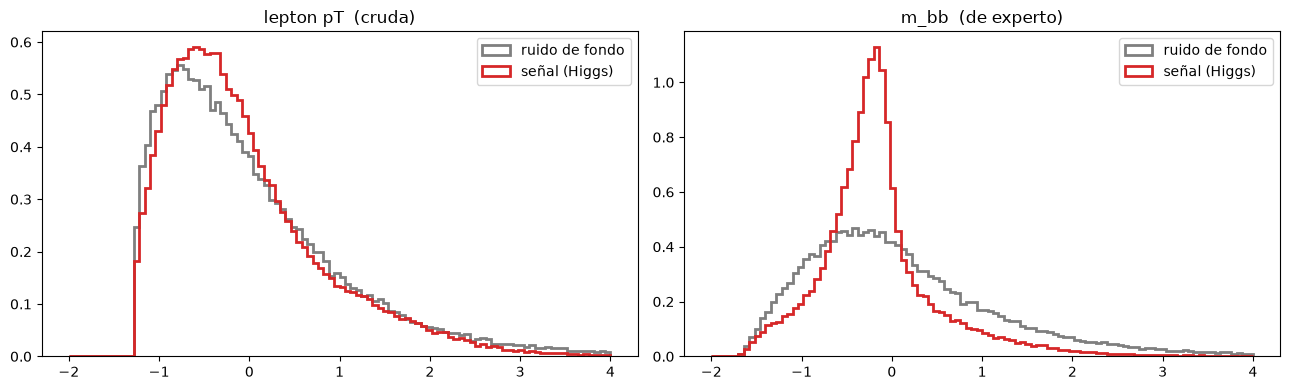

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(ejes, ["lepton pT", "m_bb"]):
    j = NOMBRES.index(col)
    for clase, nombre, color in [(0, "ruido de fondo", "tab:gray"), (1, "señal (Higgs)", "tab:red")]:
        ax.hist(X_pool[:200_000][y_pool[:200_000] == clase, j], bins=100, range=(-2, 4), density=True,
                histtype="step", lw=2, color=color, label=nombre)
    ax.set_title(f"{col}  ({'cruda' if col in CRUDAS else 'de experto'})"); ax.legend()
plt.tight_layout(); plt.show()

**Lectura:** las curvas de señal y ruido se **superponen muchísimo**: ninguna variable sola resuelve el problema (por eso es difícil y por eso los físicos inventaron variables de experto como `m_bb`, que separa un poco mejor). El modelo tendrá que **combinar** las 28 variables.

**¿De dónde sale la altura de las curvas?** El eje vertical **no es un porcentaje**: es una *densidad*. Tomemos una sola cajita del gráfico de `lepton pT` (de −0,62 a −0,56, justo en el pico rojo) y hagamos la cuenta a mano:

1. separar los choques por clase;
2. contar cuántos de esa clase caen dentro del dibujo (de −2 a 4);
3. contar cuántos caen en la cajita;
4. dividir: qué porcentaje de su clase cae en la cajita;
5. dividir por el ancho de la cajita (0,06): esa es la altura que se ve en el gráfico.

In [5]:
# Cómo se calcula la altura del histograma, paso a paso, en UNA cajita de "lepton pT"
col = "lepton pT"
ancho = (4 - (-2)) / 100                    # range=(-2, 4) y bins=100  →  cada cajita mide 0.06
desde, hasta = -0.62, -0.56                 # la cajita que vamos a revisar (justo en el pico rojo)

v = X_pool[:200_000, NOMBRES.index(col)]    # el valor de la columna en los mismos 200 000 choques del gráfico
y = y_pool[:200_000]                        # y su etiqueta (1 = Higgs, 0 = ruido)

for clase, nombre in [(1, "señal (Higgs)"), (0, "ruido de fondo")]:
    v_clase = v[y == clase]                                    # 1. solo los choques de esta clase
    en_rango = ((v_clase >= -2) & (v_clase <= 4)).sum()        # 2. cuántos caen dentro del dibujo (de -2 a 4)
    en_caja = ((v_clase >= desde) & (v_clase < hasta)).sum()   # 3. cuántos caen en la cajita
    porcentaje = en_caja / en_rango                            # 4. qué porcentaje de su clase cae en la cajita
    altura = porcentaje / ancho                                # 5. dividido por el ancho = la altura del gráfico
    print(f"{nombre}: {en_caja:,} de {en_rango:,} = {porcentaje:.2%}   →   altura = {porcentaje:.4f} / {ancho:.2f} = {altura:.2f}")

señal (Higgs): 3,741 de 105,509 = 3.55%   →   altura = 0.0355 / 0.06 = 0.59
ruido de fondo: 2,954 de 93,413 = 3.16%   →   altura = 0.0316 / 0.06 = 0.53


## 2. Los competidores

| Familia | Modelo | En una frase |
|---|---|---|
| ML clásico | **Regresión logística** | Una sola neurona: frontera recta. Línea base. |
| ML clásico | **Random Forest** | Cientos de árboles de decisión que votan. |
| ML clásico | **Gradient Boosting** | Árboles que se construyen uno tras otro corrigiendo los errores del anterior (la familia de XGBoost y LightGBM). **El rival más fuerte en datos tabulares.** |
| Deep learning | **Red neuronal (MLP)** | 3 capas ocultas de 256 neuronas, ReLU, salida para clasificación binaria. |

La red se entrena con el mismo ciclo de siempre (`zero_grad → forward → pérdida → backward → step`) y con **early stopping**: separamos el 10 % de sus datos para validar y nos quedamos con la época de menor pérdida de validación.

In [6]:
def crear_red(n_entradas=28, capas=(256, 256, 256)):
    bloques, entrada = [], n_entradas
    for ancho in capas:
        bloques += [nn.Linear(entrada, ancho), nn.ReLU()]
        entrada = ancho
    bloques.append(nn.Linear(entrada, 1))            # un logit: >0 → señal
    return nn.Sequential(*bloques)


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters())


def entrenar_red(X, y, capas=(256, 256, 256), semilla=SEMILLA, dispositivo=None, max_epocas=None, paciencia=15):
    dispositivo = dispositivo or DISPOSITIVO
    n = len(X)
    orden = np.random.default_rng(1).permutation(n)
    n_val = max(200, n // 10)
    val, tr = orden[:n_val], orden[n_val:]
    a_tensor = lambda a: torch.tensor(a, device=dispositivo)
    Xtr, ytr = a_tensor(X[tr]), a_tensor(y[tr]).unsqueeze(1)
    Xva, yva = a_tensor(X[val]), a_tensor(y[val]).unsqueeze(1)

    torch.manual_seed(semilla)
    modelo = crear_red(X.shape[1], capas).to(dispositivo)
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=1e-3, weight_decay=1e-4)
    perdida_fn = nn.BCEWithLogitsLoss()
    lote = 128 if n < 100_000 else 1024                      # lotes más grandes cuando hay muchos datos
    max_epocas = max_epocas or int(np.clip(3e6 / n, 15, 300)) # pocos datos → más épocas

    mejor, mejores_pesos, sin_mejora, t0 = np.inf, None, 0, time.time()
    for epoca in range(max_epocas):
        modelo.train()
        idx = torch.randperm(len(Xtr), device=dispositivo)
        for i in range(0, len(Xtr), lote):
            b = idx[i:i + lote]
            optimizador.zero_grad()
            perdida_fn(modelo(Xtr[b]), ytr[b]).backward()
            optimizador.step()
        modelo.eval()
        with torch.no_grad():
            val_loss = perdida_fn(modelo(Xva), yva).item()
        if val_loss < mejor:
            mejor, mejores_pesos, sin_mejora = val_loss, copy.deepcopy(modelo.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    modelo.load_state_dict(mejores_pesos)
    modelo.eval()
    return modelo, {"epocas": epoca + 1, "tiempo": time.time() - t0}


def prob_red(modelo, X, lote=200_000):
    disp = next(modelo.parameters()).device
    with torch.no_grad():
        return np.concatenate([torch.sigmoid(modelo(torch.tensor(X[i:i + lote], device=disp))).squeeze(1).cpu().numpy()
                               for i in range(0, len(X), lote)])


def modelos_clasicos():
    return {
        "Regresión logística": LogisticRegression(max_iter=1000),
        "Random Forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEMILLA),
        "Gradient Boosting": HistGradientBoostingClassifier(max_iter=500, random_state=SEMILLA),
    }

## Experimento 1 · La curva: ¿quién gana según la cantidad de datos?

Entrenamos los 4 modelos con **1 000, 3 000, 10 000, 30 000, 100 000, 300 000, 1 000 000 y 2 000 000** choques y medimos la **exactitud** en los mismos 100 000 choques de prueba. (Ojo: son los datos que **se le entregan** a cada modelo. La red y el Gradient Boosting apartan por dentro el 10 % para validar; con 2 000 000, entrenan con 1 800 000 y validan con 200 000.)

**Apuesta 1:** con 1 000 datos, ¿quién gana?
**Apuesta 2:** con 2 millones, ¿quién gana?


Con GPU en Colab tarda varios minutos (con la misma cantidad de datos, el Random Forest es el más lento).

In [7]:
TAMANOS = [1_000, 3_000, 10_000, 30_000, 100_000, 300_000, 1_000_000, 2_000_000]
if MODO_RAPIDO:
    TAMANOS = [1_000, 3_000, 10_000, 30_000, 100_000, 300_000]
RF_MAXIMO = 1_000_000          # más allá, el Random Forest necesita demasiada memoria y tiempo
if os.cpu_count() <= 4:
    RF_MAXIMO = 300_000        # Colab gratis tiene 2 núcleos: el Random Forest con 1 millón tardaría muchos minutos

resultados, finales = [], {}
for n in TAMANOS:
    Xn, yn = X_pool[:n], y_pool[:n]
    m_tr = min(n, 100_000)                   # para medir la exactitud de entrenamiento
    for nombre, modelo in modelos_clasicos().items():
        if nombre == "Random Forest" and n > RF_MAXIMO:
            continue
        t = time.time(); modelo.fit(Xn, yn); dur = time.time() - t
        resultados.append({"n": n, "modelo": nombre, "tiempo": dur,
                           "acc_train": accuracy_score(yn[:m_tr], modelo.predict(Xn[:m_tr])),
                           "acc_test": accuracy_score(y_test, modelo.predict(X_test))})
        finales[nombre] = modelo
    red, info = entrenar_red(Xn, yn)
    resultados.append({"n": n, "modelo": "Red neuronal", "tiempo": info["tiempo"],
                       "acc_train": accuracy_score(yn[:m_tr], prob_red(red, Xn[:m_tr]) > 0.5),
                       "acc_test": accuracy_score(y_test, prob_red(red, X_test) > 0.5)})
    finales["Red neuronal"] = red
    fila = {r["modelo"]: f"{100 * r['acc_test']:.1f}%" for r in resultados if r["n"] == n}
    print(f"n = {n:>9,}  |  {fila}")
json.dump(resultados, open("resultados_curva.json", "w"))

res = pd.DataFrame(resultados)

n =     1,000  |  {'Regresión logística': '63.1%', 'Random Forest': '65.6%', 'Gradient Boosting': '66.6%', 'Red neuronal': '57.5%'}
n =     3,000  |  {'Regresión logística': '63.9%', 'Random Forest': '68.4%', 'Gradient Boosting': '68.7%', 'Red neuronal': '63.6%'}
n =    10,000  |  {'Regresión logística': '64.2%', 'Random Forest': '70.4%', 'Gradient Boosting': '70.5%', 'Red neuronal': '66.1%'}
n =    30,000  |  {'Regresión logística': '64.2%', 'Random Forest': '71.3%', 'Gradient Boosting': '72.1%', 'Red neuronal': '69.7%'}
n =   100,000  |  {'Regresión logística': '64.3%', 'Random Forest': '72.0%', 'Gradient Boosting': '72.9%', 'Red neuronal': '71.8%'}
n =   300,000  |  {'Regresión logística': '64.2%', 'Random Forest': '72.8%', 'Gradient Boosting': '73.9%', 'Red neuronal': '74.0%'}
n = 1,000,000  |  {'Regresión logística': '64.2%', 'Random Forest': '73.6%', 'Gradient Boosting': '74.2%', 'Red neuronal': '76.0%'}
n = 2,000,000  |  {'Regresión logística': '64.2%', 'Gradient Boosting': '74.

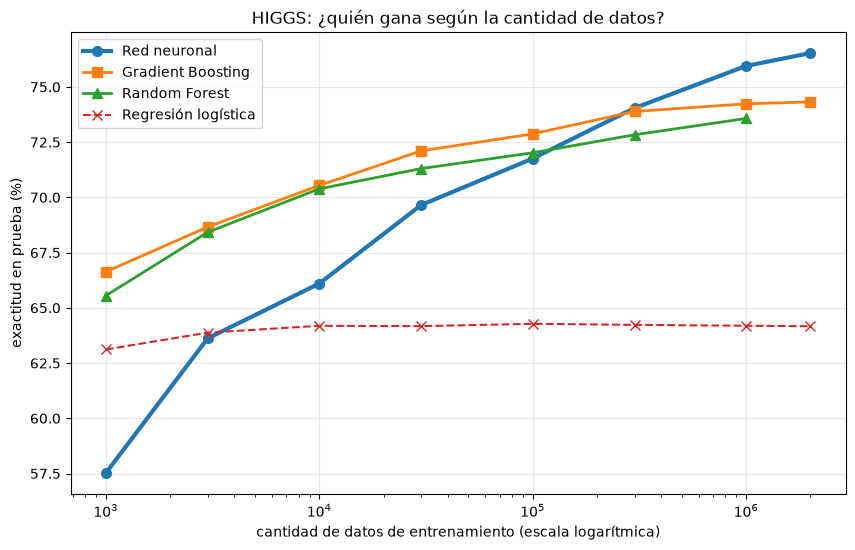

modelo,Gradient Boosting,Random Forest,Red neuronal,Regresión logística
n,,,,
1000,66.6,65.6,57.5,63.1
3000,68.7,68.4,63.6,63.9
10000,70.5,70.4,66.1,64.2
30000,72.1,71.3,69.7,64.2
100000,72.9,72.0,71.8,64.3
300000,73.9,72.8,74.0,64.2
1000000,74.2,73.6,76.0,64.2
2000000,74.3,NaN,76.5,64.2


In [8]:
ESTILO = {"Red neuronal": ("o-", 3), "Gradient Boosting": ("s-", 2), "Random Forest": ("^-", 2), "Regresión logística": ("x--", 1.5)}
plt.figure(figsize=(10, 6))
for modelo, (marca, grosor) in ESTILO.items():
    d = res[res.modelo == modelo]
    plt.plot(d.n, 100 * d.acc_test, marca, lw=grosor, ms=7, label=modelo)
plt.xscale("log"); plt.grid(alpha=0.3)
plt.xlabel("cantidad de datos de entrenamiento (escala logarítmica)"); plt.ylabel("exactitud en prueba (%)")
plt.title("HIGGS: ¿quién gana según la cantidad de datos?"); plt.legend()
plt.show()

tabla_exactitud = res.pivot(index="n", columns="modelo", values="acc_test").mul(100).round(1)
tabla_exactitud

**Lectura (la idea central de la clase):**
* **Con pocos datos gana el ML clásico.** Con 1 000 choques, Gradient Boosting y Random Forest le sacan varios puntos a la red: la red tiene más de cien mil parámetros (139 265) y casi nada con qué ajustarlos.
* **La red tiene "hambre de datos".** Los árboles mejoran despacio y se van **aplanando**; la red sube más rápido con cada multiplicación de datos.
* **El cruce:** entre 100 000 y 300 000 datos la red alcanza y pasa a los árboles. Con 2 millones, les saca más de 2 puntos al mejor modelo clásico.
* La regresión logística (una sola neurona, frontera recta) se queda abajo sin importar cuántos datos le demos: **sin capacidad, los datos no sirven**.


## Experimento 2 · ¿Cuánto cuesta? Tiempos y CPU vs. GPU

Diapositiva 14, otro mito: *"Needs a huge GPU: Only in specific research projects. Use the cloud!"*. Primero, ¿cuánto **costó entrenar** cada modelo en el experimento anterior? La tabla da los **segundos de entrenamiento** de cada modelo para cada cantidad de datos, cada uno en su máquina natural: **la red en la GPU** y **los otros tres en la CPU** (scikit-learn no usa GPU). No es una comparación CPU contra GPU: esa viene en la celda siguiente, con la misma red.

In [9]:
tabla_tiempos = res.pivot(index="n", columns="modelo", values="tiempo").round(1)
tabla_tiempos

modelo,Gradient Boosting,Random Forest,Red neuronal,Regresión logística
n,,,,
1000,3.1,0.1,0.8,0.0
3000,1.1,0.2,0.5,0.0
10000,1.3,0.3,1.7,0.0
30000,0.4,0.9,5.0,0.0
100000,0.9,3.5,2.9,0.0
300000,5.0,12.9,5.7,0.1
1000000,15.6,58.0,20.9,0.5
2000000,33.7,NaN,43.2,1.1


Y ahora la **misma red**, con los **mismos datos** (300 000 choques), entrenada **una época** en CPU y en GPU:

In [10]:
def tiempo_una_epoca(dispositivo, n=300_000):
    Xt = torch.tensor(X_pool[:n], device=dispositivo); yt = torch.tensor(y_pool[:n], device=dispositivo).unsqueeze(1)
    torch.manual_seed(SEMILLA)
    m = crear_red().to(dispositivo); opt = torch.optim.AdamW(m.parameters(), lr=1e-3); f = nn.BCEWithLogitsLoss()
    if dispositivo == "cuda": torch.cuda.synchronize()
    t = time.time()
    for i in range(0, n, 1024):
        opt.zero_grad(); f(m(Xt[i:i + 1024]), yt[i:i + 1024]).backward(); opt.step()
    if dispositivo == "cuda": torch.cuda.synchronize()
    return time.time() - t

t_cpu = tiempo_una_epoca("cpu")
print(f"CPU ({os.cpu_count()} núcleos): {t_cpu:.1f} s por época")
if DISPOSITIVO == "cuda":
    tiempo_una_epoca("cuda")                 # la primera vez la GPU "calienta"
    t_gpu = tiempo_una_epoca("cuda")
    print(f"GPU ({torch.cuda.get_device_name(0)}): {t_gpu:.2f} s por época  →  {t_cpu / t_gpu:.0f} veces más rápida")

CPU (24 núcleos): 1.3 s por época
GPU (NVIDIA GeForce RTX 5070 Laptop GPU): 0.40 s por época  →  3 veces más rápida


**Lectura:**
* Con pocos datos, los árboles entrenan en fracciones de segundo: para tablas pequeñas, **no necesitan ninguna GPU**.
* Con millones de datos, el Random Forest se vuelve lento y pesado en memoria (por eso lo detenemos en 1 millón), mientras la red en GPU escala bien.
* La GPU no es "gigante": una T4 gratuita de Colab basta para este experimento con 2 millones de datos. *"Use the cloud!"*

## Experimento 3 · Red pequeña, mediana y grande: ¿el tamaño depende de los datos?

Cuatro redes de distinto tamaño, entrenadas con 1 000, 10 000, 100 000 y 1 000 000 de datos.

**Apuesta:** con 10 000 datos, ¿gana la red más grande?

n =     1,000 listo
n =    10,000 listo
n =   100,000 listo
n = 1,000,000 listo


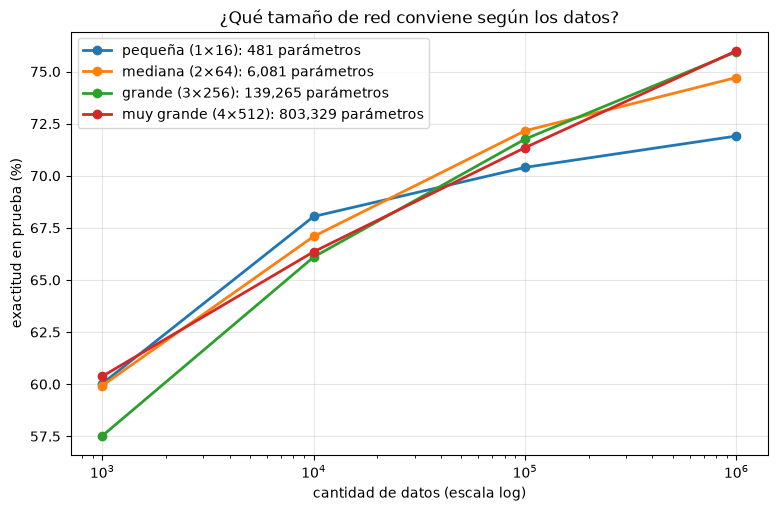

red,grande (3×256),mediana (2×64),muy grande (4×512),pequeña (1×16)
n,,,,
1000,57.5,59.9,60.4,60.0
10000,66.1,67.1,66.4,68.0
100000,71.8,72.2,71.3,70.4
1000000,76.0,74.7,76.0,71.9


In [11]:
REDES = {"pequeña (1×16)": (16,), "mediana (2×64)": (64, 64), "grande (3×256)": (256, 256, 256),
         "muy grande (4×512)": (512, 512, 512, 512)}
TAMANOS_3 = [1_000, 10_000, 100_000] if MODO_RAPIDO else [1_000, 10_000, 100_000, 1_000_000]

filas = []
for n in TAMANOS_3:
    for nombre, capas in REDES.items():
        red, _ = entrenar_red(X_pool[:n], y_pool[:n], capas=capas)
        filas.append({"n": n, "red": nombre, "parametros": contar_parametros(red),
                      "acc_test": accuracy_score(y_test, prob_red(red, X_test) > 0.5)})
    print(f"n = {n:>9,} listo")
tam = pd.DataFrame(filas)

plt.figure(figsize=(9, 5.5))
for nombre in REDES:
    d = tam[tam.red == nombre]
    plt.plot(d.n, 100 * d.acc_test, "o-", lw=2, label=f"{nombre}: {d.parametros.iloc[0]:,} parámetros")
plt.xscale("log"); plt.grid(alpha=0.3); plt.legend()
plt.xlabel("cantidad de datos (escala log)"); plt.ylabel("exactitud en prueba (%)")
plt.title("¿Qué tamaño de red conviene según los datos?"); plt.show()
tam.pivot(index="n", columns="red", values="acc_test").mul(100).round(1)

**Lectura:**
* Con **pocos datos**, la red **pequeña** rinde igual o mejor que las grandes: las grandes tienen demasiados parámetros para tan pocos ejemplos.
* Con **muchos datos**, la pequeña se **estanca** (no tiene capacidad) y las grandes siguen subiendo.
* **El tamaño del modelo tiene que crecer junto con los datos.** Esta es la idea detrás de los modelos gigantes de hoy (como los LLM): modelos enormes **y** cantidades enormes de datos.

## Experimento 4 · ¿Red ancha o red profunda?

El **Teorema de Aproximación Universal** (diapositivas 19–21) dice que **una sola capa oculta** con suficientes neuronas puede aproximar cualquier función. Entonces, ¿para qué capas?

Comparación justa: **el mismo presupuesto** de ≈ 63 000–72 000 parámetros, repartido de 4 formas distintas.

**Apuesta:** ¿gana la ancha (1 capa) o la profunda (8 capas)?

n =   100,000 listo
n = 1,000,000 listo


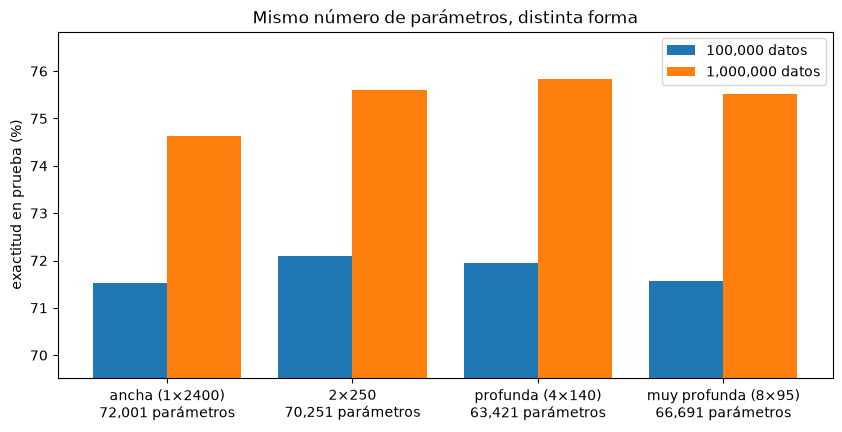

n,100000,1000000
forma,,
ancha (1×2400),71.5,74.6
2×250,72.1,75.6
profunda (4×140),71.9,75.8
muy profunda (8×95),71.6,75.5


In [12]:
FORMAS = {"ancha (1×2400)": (2400,), "2×250": (250, 250), "profunda (4×140)": (140,) * 4, "muy profunda (8×95)": (95,) * 8}
TAMANOS_4 = [100_000] if MODO_RAPIDO else [100_000, 1_000_000]

filas = []
for n in TAMANOS_4:
    for nombre, capas in FORMAS.items():
        red, _ = entrenar_red(X_pool[:n], y_pool[:n], capas=capas)
        filas.append({"n": n, "forma": nombre, "capas": len(capas), "parametros": contar_parametros(red),
                      "acc_test": accuracy_score(y_test, prob_red(red, X_test) > 0.5)})
    print(f"n = {n:>9,} listo")
forma = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(10, 4.5))
ancho_barra = 0.8 / len(TAMANOS_4)
for k, n in enumerate(TAMANOS_4):
    d = forma[forma.n == n]
    ax.bar(np.arange(len(FORMAS)) + k * ancho_barra, 100 * d.acc_test, ancho_barra, label=f"{n:,} datos")
ax.set_xticks(np.arange(len(FORMAS)) + ancho_barra * (len(TAMANOS_4) - 1) / 2)
ax.set_xticklabels([f"{f}\n{p:,} parámetros" for f, p in zip(FORMAS, forma.parametros[:len(FORMAS)])])
lo = 100 * forma.acc_test.min()
ax.set_ylim(lo - 2, 100 * forma.acc_test.max() + 1); ax.set_ylabel("exactitud en prueba (%)"); ax.legend()
ax.set_title("Mismo número de parámetros, distinta forma"); plt.show()
forma.pivot(index="forma", columns="n", values="acc_test").mul(100).round(1).loc[list(FORMAS)]

### 4b · ¿Y con un presupuesto más grande?

Repetimos la comparación con **≈ 200 000 parámetros** (unas 3 veces más), repartidos de nuevo en 1, 2, 4 y 8 capas. ¿Se mantiene el resultado?

n =   100,000 listo
n = 1,000,000 listo


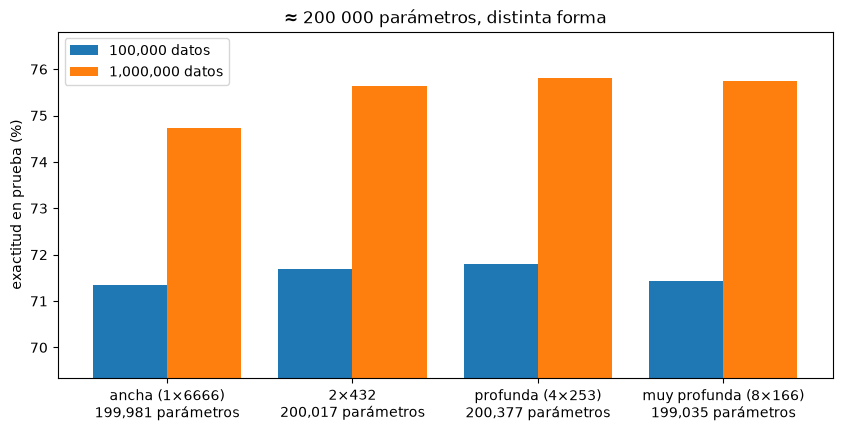

n,100000,1000000
forma,,
ancha (1×6666),71.3,74.7
2×432,71.7,75.6
profunda (4×253),71.8,75.8
muy profunda (8×166),71.4,75.7


In [13]:
FORMAS_200K = {"ancha (1×6666)": (6666,), "2×432": (432, 432), "profunda (4×253)": (253,) * 4, "muy profunda (8×166)": (166,) * 8}
TAMANOS_4 = [100_000] if MODO_RAPIDO else [100_000, 1_000_000]     # los mismos tamaños del experimento 4

filas = []
for n in TAMANOS_4:
    for nombre, capas in FORMAS_200K.items():
        red, _ = entrenar_red(X_pool[:n], y_pool[:n], capas=capas)
        filas.append({"n": n, "forma": nombre, "capas": len(capas), "parametros": contar_parametros(red),
                      "acc_test": accuracy_score(y_test, prob_red(red, X_test) > 0.5)})
    print(f"n = {n:>9,} listo")
forma_200k = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(10, 4.5))
ancho_barra = 0.8 / len(TAMANOS_4)
for k, n in enumerate(TAMANOS_4):
    d = forma_200k[forma_200k.n == n]
    ax.bar(np.arange(len(FORMAS_200K)) + k * ancho_barra, 100 * d.acc_test, ancho_barra, label=f"{n:,} datos")
ax.set_xticks(np.arange(len(FORMAS_200K)) + ancho_barra * (len(TAMANOS_4) - 1) / 2)
ax.set_xticklabels([f"{f}\n{p:,} parámetros" for f, p in zip(FORMAS_200K, forma_200k.parametros[:len(FORMAS_200K)])])
lo = 100 * forma_200k.acc_test.min()
ax.set_ylim(lo - 2, 100 * forma_200k.acc_test.max() + 1); ax.set_ylabel("exactitud en prueba (%)"); ax.legend()
ax.set_title("≈ 200 000 parámetros, distinta forma"); plt.show()
forma_200k.pivot(index="forma", columns="n", values="acc_test").mul(100).round(1).loc[list(FORMAS_200K)]

### 4c · ¿Y con 2 millones de datos?

Las cuatro formas de **≈ 70 000 parámetros**, ahora con **todos los datos**: 2 000 000. ¿Se mantiene el orden? ¿Cuánto suben?

**¿Por qué no corremos también las de ≈ 200 000?** Por la **memoria de la GPU**. Al final de cada época, la red mide la validación con los 200 000 choques de una vez, y cada capa oculta produce una tabla de 200 000 × (neuronas de la capa) números de 4 bytes:

| Red | Tabla de una capa en la validación | ¿Cabe en 8,5 GB? |
|---|---|---|
| ancha 1×2400 (≈ 70 000) | 200 000 × 2 400 × 4 bytes ≈ **1,9 GB** (≈ 3,8 GB con la ReLU) | sí |
| ancha 1×6666 (≈ 200 000) | 200 000 × 6 666 × 4 bytes ≈ **5,3 GB** (≈ 10,7 GB con la ReLU) | **no** |

La ancha de 200 000 parámetros no cabe en la GPU de un portátil (8,5 GB). En el portátil del monitor (GPU RTX 5070), las 4 redes de esta celda tardaron en total unos **3 minutos** (28 + 33 + 45 + 64 segundos); en Colab puede tardar más.

ancha (1×2400): listo (28 s)
2×250: listo (33 s)
profunda (4×140): listo (45 s)
muy profunda (8×95): listo (64 s)


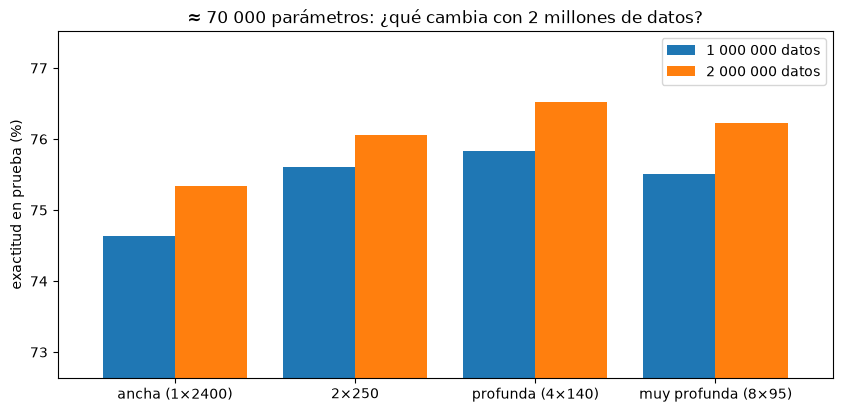

,1 000 000 datos,2 000 000 datos
forma,,
ancha (1×2400),74.6,75.3
2×250,75.6,76.1
profunda (4×140),75.8,76.5
muy profunda (8×95),75.5,76.2


In [14]:
FORMAS_70K = {"ancha (1×2400)": (2400,), "2×250": (250, 250), "profunda (4×140)": (140,) * 4, "muy profunda (8×95)": (95,) * 8}
N_GRANDE = 2_000_000                    # todos los datos de entrenamiento disponibles

if MODO_RAPIDO:
    print("Sin GPU no corremos 2 millones de datos (tardaría demasiado).")
else:
    filas = []
    for nombre, capas in FORMAS_70K.items():
        red, info = entrenar_red(X_pool[:N_GRANDE], y_pool[:N_GRANDE], capas=capas)
        filas.append({"forma": nombre, "parametros": contar_parametros(red), "epocas": info["epocas"],
                      "acc_test": accuracy_score(y_test, prob_red(red, X_test) > 0.5)})
        print(f"{nombre}: listo ({info['tiempo']:.0f} s)")
        del red; torch.cuda.empty_cache()   # liberar la memoria de la GPU antes de la siguiente red
    forma_2m = pd.DataFrame(filas).set_index("forma")

    tabla = pd.DataFrame({"2 000 000 datos": 100 * forma_2m.acc_test})
    if "forma" in globals():               # si ya se corrió la celda 27, comparamos con 1 millón
        tabla.insert(0, "1 000 000 datos", 100 * forma[forma.n == 1_000_000].set_index("forma").acc_test)

    ax = tabla.plot.bar(figsize=(10, 4.5), rot=0, width=0.8)
    ax.set_ylim(tabla.min().min() - 2, tabla.max().max() + 1)
    ax.set_ylabel("exactitud en prueba (%)"); ax.set_xlabel("")
    ax.set_title("≈ 70 000 parámetros: ¿qué cambia con 2 millones de datos?"); plt.show()
    display(tabla.round(1))

**Lectura (experimento 4 completo: 4, 4b y 4c):**

| Forma | ≈ 70 000 parám., 1 000 000 datos | ≈ 70 000 parám., **2 000 000 datos** | ≈ 200 000 parám., 1 000 000 datos |
|---|---|---|---|
| ancha (1 capa) | 74.6 | **75.3** | 74.7 |
| 2 capas | 75.6 | **76.1** | 75.6 |
| profunda (4 capas) | 75.8 | **76.5** | 75.8 |
| muy profunda (8 capas) | 75.5 | **76.2** | 75.7 |

* Con **100 000 datos**, en los dos presupuestos las cuatro formas quedan prácticamente empatadas (diferencias de unas décimas).
* Con **1 millón de datos**, la red **ancha de una sola capa queda de última** y las profundas le ganan por cerca de 1 punto **con el mismo número de parámetros**.
* **Triplicar los parámetros casi no cambia nada** (columna 1 vs. columna 3): la ancha pasa de 74.6 a 74.7. No le faltan perillas, le falta **forma**.
* **Duplicar los datos sí sube a todas** (columna 1 vs. columna 2): entre 0.5 y 0.7 puntos. Con 1 millón, el límite eran los datos, no las perillas.
* **El orden nunca cambia:** la ancha siempre de última, la de 4 capas siempre arriba, y pasar de 4 a 8 capas no mejora.

¿Por qué?
* El teorema garantiza que la red ancha **puede** aproximar la función, pero no dice **cuántas neuronas** necesita ni si el entrenamiento las va a encontrar.
* Las capas permiten **componer**: la primera capa detecta combinaciones simples de las variables, la siguiente combina esas combinaciones... Con el mismo presupuesto, la profundidad suele aprovechar mejor los parámetros. Es la razón por la que se llama **deep** learning.
* Pero más profundo no siempre es mejor: redes muy profundas y delgadas son más difíciles de entrenar (los gradientes tienen que atravesar muchas capas). Ese problema se resuelve con técnicas que veremos más adelante.

## Experimento 5 · ¿La red aprende sola las variables de los físicos?

Recuerden: las 7 variables "de experto" se **calculan a partir de las 21 crudas**. Entrenamos el mejor modelo clásico y la red con:
* solo las **21 crudas**,
* solo las **7 de experto**,
* **todas** (28).

**Apuesta:** ¿a quién le duele más quitarle las variables de experto: a los árboles o a la red?

21 crudas listo
7 de experto listo
28 (todas) listo


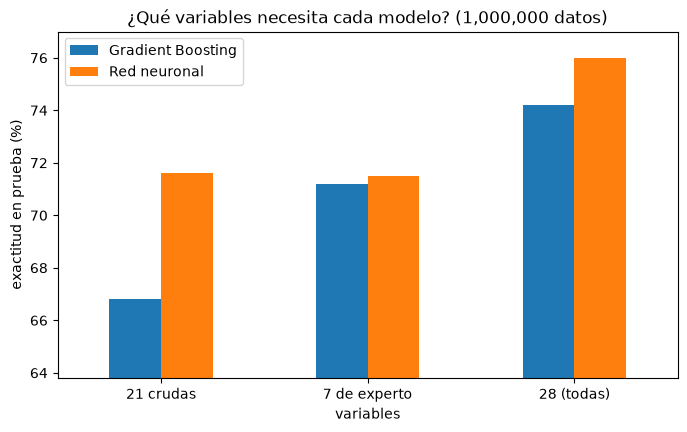

,Gradient Boosting,Red neuronal
variables,,
21 crudas,66.8,71.6
7 de experto,71.2,71.5
28 (todas),74.2,76.0


In [15]:
n5 = 100_000 if MODO_RAPIDO else 1_000_000
CONJUNTOS = {"21 crudas": slice(0, 21), "7 de experto": slice(21, 28), "28 (todas)": slice(0, 28)}
filas = []
for nombre, cols in CONJUNTOS.items():
    gb = HistGradientBoostingClassifier(max_iter=500, random_state=SEMILLA).fit(X_pool[:n5, cols], y_pool[:n5])
    red, _ = entrenar_red(X_pool[:n5, cols], y_pool[:n5])
    filas.append({"variables": nombre,
                  "Gradient Boosting": 100 * accuracy_score(y_test, gb.predict(X_test[:, cols])),
                  "Red neuronal": 100 * accuracy_score(y_test, prob_red(red, X_test[:, cols]) > 0.5)})
    print(nombre, "listo")
var = pd.DataFrame(filas).set_index("variables").round(1)

var.plot.bar(figsize=(8, 4.5), rot=0, ylim=(var.values.min() - 3, var.values.max() + 1))
plt.ylabel("exactitud en prueba (%)"); plt.title(f"¿Qué variables necesita cada modelo? ({n5:,} datos)"); plt.show()
var

### 5b · ¿Y con 2 millones de datos?

El mismo experimento con **todos los datos** (2 000 000). Si la red "aprende a picar" con más práctica, con el doble de datos debería **acercarse** más a lo que logra con las 28 columnas. ¿Pasa? (Son 6 entrenamientos con 2 millones: tarda unos minutos.)

21 crudas listo
7 de experto listo
28 (todas) listo


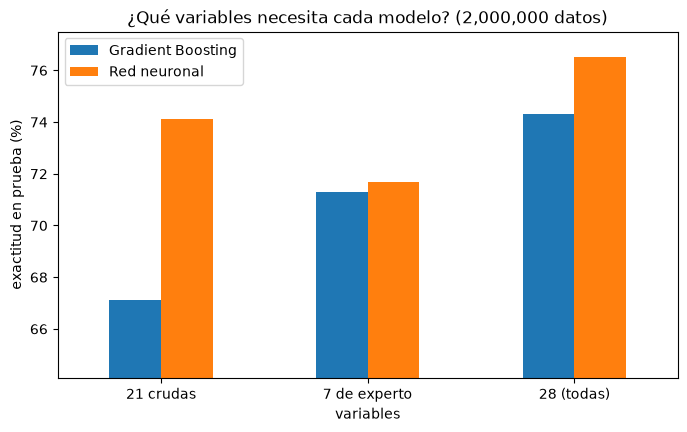

1 000 000 datos                2 000 000 datos             
             Gradient Boosting Red neuronal Gradient Boosting Red neuronal
variables                                                                 
21 crudas                 66.8         71.6              67.1         74.1
7 de experto              71.2         71.5              71.3         71.7
28 (todas)                74.2         76.0              74.3         76.5

In [20]:
n5b = 2_000_000                         # todos los datos de entrenamiento disponibles
CONJUNTOS = {"21 crudas": slice(0, 21), "7 de experto": slice(21, 28), "28 (todas)": slice(0, 28)}

if MODO_RAPIDO:
    print("Sin GPU no corremos 2 millones de datos (tardaría demasiado).")
else:
    filas = []
    for nombre, cols in CONJUNTOS.items():
        gb = HistGradientBoostingClassifier(max_iter=500, random_state=SEMILLA).fit(X_pool[:n5b, cols], y_pool[:n5b])
        red, _ = entrenar_red(X_pool[:n5b, cols], y_pool[:n5b])
        filas.append({"variables": nombre,
                      "Gradient Boosting": 100 * accuracy_score(y_test, gb.predict(X_test[:, cols])),
                      "Red neuronal": 100 * accuracy_score(y_test, prob_red(red, X_test[:, cols]) > 0.5)})
        print(nombre, "listo")
        del red; torch.cuda.empty_cache()
    var_2m = pd.DataFrame(filas).set_index("variables").round(1)

    var_2m.plot.bar(figsize=(8, 4.5), rot=0, ylim=(var_2m.values.min() - 3, var_2m.values.max() + 1))
    plt.ylabel("exactitud en prueba (%)"); plt.title(f"¿Qué variables necesita cada modelo? ({n5b:,} datos)"); plt.show()
    if "var" in globals():                  # si ya se corrió la celda anterior, comparamos 1 millón con 2 millones
        display(pd.concat({"1 000 000 datos": var, "2 000 000 datos": var_2m}, axis=1))
    else:
        display(var_2m)

**Lectura (1 millón y 2 millones de datos):**

| variables | Gradient Boosting, 1 M | Red, 1 M | Gradient Boosting, **2 M** | Red, **2 M** |
|---|---|---|---|---|
| 21 crudas | 66.8 | 71.6 | 67.1 | **74.1** |
| 7 de experto | 71.2 | 71.5 | 71.3 | 71.7 |
| 28 (todas) | 74.2 | 76.0 | 74.3 | 76.5 |

* Al quitar las variables de experto (quedarse con las 21 crudas), **los árboles pierden mucho más que la red**: con 1 millón, el Gradient Boosting pierde 7.4 puntos y la red 4.4.
* Con 1 millón, la red con **solo las crudas** (71.6) queda al nivel del Gradient Boosting con **solo las 7 variables de los físicos** (71.2).
* **Con el doble de datos, la red con solo las crudas sube 2.5 puntos** (71.6 → 74.1) y el Gradient Boosting casi nada (66.8 → 67.1). La distancia de la red entre "solo crudas" y "todas" baja de 4.4 a 2.4 puntos: **con más datos, la red construye mejor sus propias variables**. Con 2 millones, la red con solo lo que mide el detector (74.1) **casi iguala al Gradient Boosting con todas las variables** (74.3).
* Con **solo las 7 de experto**, los dos quedan casi iguales (la red, unas 4 décimas arriba) y casi no mejoran con más datos: esas 7 variables resumen mucho, pero no toda la información.
* La red no recupera todo: con las 28 sigue siendo mejor. (El artículo original, con una red de 5 capas de 300 neuronas y 10.5 millones de choques, casi lo logró: AUC 0.880 con solo las crudas frente a 0.885 con todas.)

Esta es **la diferencia de fondo entre ML y DL**:
* En **ML clásico**, el humano diseña las variables (*feature engineering*) y el modelo las combina.
* En **DL**, la red aprende sus propias **representaciones** en las capas ocultas. Con suficientes datos, puede construir por sí misma algo equivalente a lo que un experto diseñó a mano.

Fue uno de los hallazgos del artículo de 2014: la red profunda con solo las variables crudas competía con los mejores métodos que usaban las variables de los físicos.

## Experimento 6 · Sobreajuste según la cantidad de datos

Del experimento 1 guardamos también la exactitud en **entrenamiento**. Comparémosla con la de **prueba**:

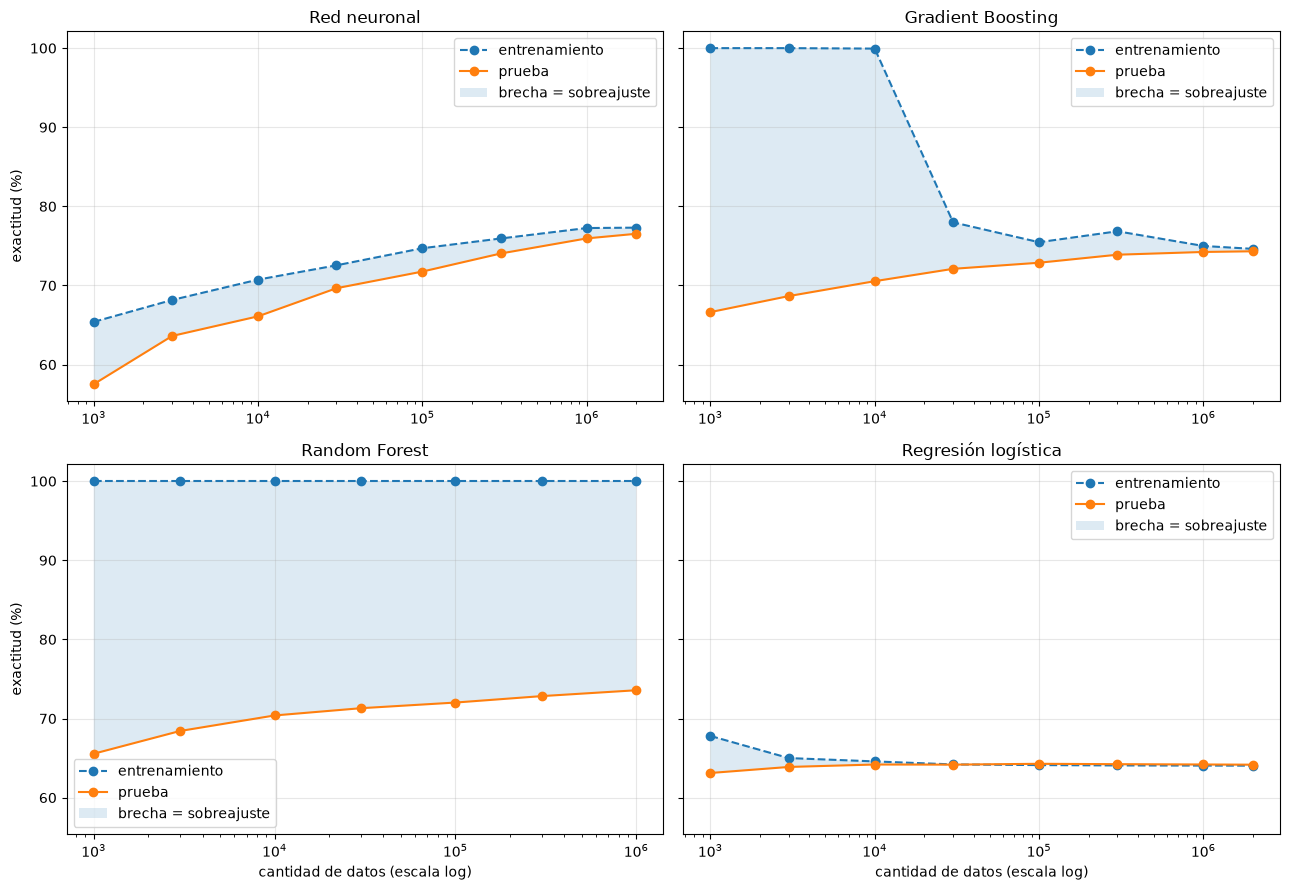

modelo   Red neuronal               Gradient Boosting                \
        entrenamiento prueba brecha     entrenamiento prueba brecha   
n                                                                     
1000             65.4   57.5    7.9             100.0   66.6   33.4   
3000             68.2   63.6    4.5             100.0   68.7   31.3   
10000            70.7   66.1    4.6              99.9   70.5   29.4   
30000            72.5   69.7    2.9              78.0   72.1    5.9   
100000           74.7   71.8    2.9              75.5   72.9    2.6   
300000           75.9   74.0    1.9              76.8   73.9    3.0   
1000000          77.3   76.0    1.3              75.0   74.2    0.8   
2000000          77.3   76.5    0.8              74.6   74.3    0.3   

modelo  Random Forest               Regresión logística                
        entrenamiento prueba brecha       entrenamiento prueba brecha  
n                                                                      
1000            100.0   65.6   34.4                67.8   63.1    4.7  
3000            100.0   68.4   31.6                65.0   63.9    1.1  
10000           100.0   70.4   29.6                64.6   64.2    0.4  
30000           100.0   71.3   28.7                64.2   64.2    0.0  
100000          100.0   72.0   28.0                64.1   64.3   -0.2  
300000          100.0   72.8   27.2                64.1   64.2   -0.2  
1000000         100.0   73.6   26.4                64.1   64.2   -0.1  
2000000           NaN    NaN    NaN                64.0   64.2   -0.1

In [23]:
if "res" not in globals():              # si en esta sesión no se corrió el experimento 1, usamos sus resultados guardados
    res = pd.DataFrame(json.load(open("resultados_curva.json")))

MODELOS = ["Red neuronal", "Gradient Boosting", "Random Forest", "Regresión logística"]
fig, ejes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
for ax, modelo in zip(ejes.flat, MODELOS):
    d = res[res.modelo == modelo]
    ax.plot(d.n, 100 * d.acc_train, "o--", label="entrenamiento")
    ax.plot(d.n, 100 * d.acc_test, "o-", label="prueba")
    ax.fill_between(d.n, 100 * d.acc_test, 100 * d.acc_train, alpha=0.15, label="brecha = sobreajuste")
    ax.set_xscale("log"); ax.set_title(modelo); ax.grid(alpha=0.3); ax.legend()
for ax in ejes[1]:
    ax.set_xlabel("cantidad de datos (escala log)")
for ax in ejes[:, 0]:
    ax.set_ylabel("exactitud (%)")
plt.tight_layout(); plt.show()

# Tabla completa: para cada modelo, su exactitud en entrenamiento, en prueba y la brecha (entrenamiento − prueba)
tabla = res.assign(entrenamiento=100 * res.acc_train, prueba=100 * res.acc_test,
                   brecha=100 * (res.acc_train - res.acc_test))
tabla = tabla.pivot(index="n", columns="modelo", values=["entrenamiento", "prueba", "brecha"]).round(1)
tabla = tabla.swaplevel(axis=1)[MODELOS]   # agrupar las columnas por modelo
tabla

**Lectura:**
* Con pocos datos, los modelos **memorizan**: exactitud de entrenamiento muy alta y de prueba mucho más baja (la **brecha** sombreada).
* A medida que crecen los datos, la brecha se **cierra**: es más difícil memorizar 2 millones de ejemplos que aprender el patrón. (Miren la tabla: el Gradient Boosting pasa de 33 puntos de brecha a menos de 1.)
* El salto del **Gradient Boosting** entre 10 000 y 30 000 datos: con **más de 10 000** activa sola su parada temprana (aparta el 10 % para validar). Con 30 000 se detiene en 96 árboles en vez de 500 y deja de memorizar (de 99.9 % a 78 % en entrenamiento).
* La **red neuronal** tiene la franja angosta en todos los tamaños (de 7,9 a 0,8 puntos): el early stopping la detiene antes de memorizar. Con 2 millones saca la nota más alta en prueba (76,5).
* La **regresión logística** tiene las dos líneas pegadas en 64 % y casi no hay franja. No es el mejor modelo: no memoriza porque es demasiado simple, y tampoco aprende más con más datos (**subajuste**). Una brecha de cero solo es buena noticia si la prueba está arriba.
* Caso especial: el **Random Forest** saca 100 % en entrenamiento en todos los tamaños, porque sus árboles crecen hasta memorizar cada ejemplo. Aun así mejora en prueba, porque **promediar** 100 árboles distintos cancela buena parte de esa memorización. Sus árboles **crecen con los datos** (148 hojas con 1 000 datos, 14 031 con 100 000), así que siempre le cabe todo. No se valida porque no hay nada que detener: más árboles nunca lo empeoran.
* **¿Por qué unos llegan a 100 % y otros no?** Para memorizar hacen falta dos cosas: **poder** (capacidad) y que **nada lo frene**. El Random Forest puede (árboles sin límite) y nada lo frena: 100 %. El Gradient Boosting hasta 10 000 datos tampoco valida: 100 %. La red podría (sin early stopping llega a 100 % con 1 000 datos), pero siempre valida y la parada temprana la detiene. La regresión logística no puede: solo tiene 29 números y una frontera plana.
* **Más datos es la mejor regularización que existe.** Dropout y L2 (diapositiva 58) son la segunda mejor opción cuando no se pueden conseguir más datos.

## Cierre: ¿cuándo usar ML clásico y cuándo deep learning?

Construyamos la respuesta con lo que **medimos hoy**:

| Situación | Mejor opción | Evidencia de hoy |
|---|---|---|
| Pocos datos tabulares (miles) | **ML clásico** (Gradient Boosting, Random Forest) | Experimento 1: ganan con 1 000 – 30 000 datos |
| Millones de datos tabulares con relaciones complejas | **Deep learning** puede ganar | Experimento 1: la red pasa adelante desde ~300 000 |
| Poco tiempo o sin GPU | **ML clásico** | Experimento 2: entrena en segundos en CPU |
| El modelo debe crecer con los datos | **Deep learning** escala | Experimento 3: redes grandes solo valen con muchos datos |
| Sin un experto que diseñe variables | **Deep learning** aprende representaciones | Experimento 5 |
| Imágenes, texto, audio, video | **Deep learning** (casi siempre) | Lo veremos desde la Sesión 2 (CNN) |
| Datos nuevos muy distintos a los de entrenamiento | **Ninguno es confiable** | Experimento 7 (reto 5) |

> **La respuesta de un buen científico de datos a "¿ML o DL?" es: "depende... y lo compruebo con un experimento".**

## Retos para entregar

Los retos 1 a 4 los programan ustedes. Los retos 5 y 6 ya tienen el código listo más abajo: córranlo y respondan las preguntas que hay al final de cada uno.

1. **Repetir con otra semilla:** cambien `SEMILLA` y repitan el experimento 1 (o solo 3 tamaños). ¿Se mantiene el cruce? ¿En qué tamaño exactamente?
2. **Mejoren la red:** con 300 000 datos, prueben otra tasa de aprendizaje, Dropout o más capas. ¿Logran que la red gane desde menos datos?
3. **Combinen modelos:** con 1 millón de datos, promedien las probabilidades de la red y del Gradient Boosting. ¿El "combo" le gana a los dos? (Es lo que hacen muchos equipos ganadores en competencias.)
4. **Pregunta de industria:** den un ejemplo real (en Colombia o el mundo) donde una empresa tenga **millones** de datos tabulares y otro donde tenga solo **miles**. ¿Qué modelo recomendarían en cada caso y por qué?
5. **Experimento 7 · Extrapolación:** ¿qué pasa cuando le pedimos al modelo predicciones fuera de lo que vio? (código listo más abajo, 4 preguntas).
6. **Experimento 8 · La matriz de confusión en lenguaje de físicos:** ¿qué cuesta más, un falso descubrimiento o un Higgs perdido?, y ¿qué pasa si exigimos más certeza? (código listo más abajo, 4 preguntas; usa los modelos del experimento 1, así que corran antes todo el cuaderno).

### Reto 5 · Experimento 7: ¿Qué pasa fuera de lo que el modelo vio?

Diapositiva 20: *"It doesn't matter if the neural network fails outside of its trained range, because that's not its goal."* Comprobémoslo con un ejemplo en una dimensión que todos puedan ver: entrenamos con datos **entre 0 y 10** y pedimos predicciones **de −5 a 20**.

In [ ]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
rng = np.random.default_rng(0)
f_real = lambda x: 0.5 * x + np.sin(x)                       # tendencia + oscilación
x1 = rng.uniform(0, 10, 400); y1 = f_real(x1) + rng.normal(0, 0.3, 400)
xs = np.linspace(-5, 20, 500)

rf1 = RandomForestRegressor(300, random_state=0).fit(x1[:, None], y1).predict(xs[:, None])
gb1 = HistGradientBoostingRegressor(random_state=0).fit(x1[:, None], y1).predict(xs[:, None])
torch.manual_seed(0)
red1 = nn.Sequential(nn.Linear(1, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
opt = torch.optim.Adam(red1.parameters(), lr=1e-2)
Xt1, yt1 = torch.tensor((x1[:, None] - 5) / 3, dtype=torch.float32), torch.tensor(y1[:, None], dtype=torch.float32)
for _ in range(3000):
    opt.zero_grad(); nn.functional.mse_loss(red1(Xt1), yt1).backward(); opt.step()
nn1 = red1(torch.tensor((xs[:, None] - 5) / 3, dtype=torch.float32)).detach().numpy().ravel()

plt.figure(figsize=(10, 5))
plt.axvspan(0, 10, color="gray", alpha=0.12, label="zona con datos de entrenamiento")
plt.scatter(x1, y1, s=5, c="k", alpha=0.4)
plt.plot(xs, f_real(xs), "k--", label="función real")
plt.plot(xs, rf1, label="Random Forest"); plt.plot(xs, gb1, label="Gradient Boosting"); plt.plot(xs, nn1, lw=2.5, label="Red neuronal")
plt.ylim(-6, 16); plt.legend(fontsize=9); plt.title("Extrapolación: predicciones fuera del rango de entrenamiento"); plt.show()

**Preguntas del reto 5 (respondan en una celda de texto debajo):**
1. **Dentro** de la zona gris (de 0 a 10), ¿qué tan bien siguen los tres modelos la función real?
2. **Fuera** de la zona gris (antes de 0 y después de 10), describan qué hace cada modelo. ¿Por qué los árboles se quedan **planos**? *Pista: ¿qué guarda cada hoja de un árbol?*
3. ¿Por qué la red sigue una **línea recta** y no la curva real? *Pista: ¿de qué está hecha una función con ReLU?*
4. En HIGGS, ¿nos preocupa este problema? ¿Por qué? Den un ejemplo real (precios, clima, sensores) donde los datos nuevos puedan salir del rango de entrenamiento, y digan qué harían.

### Reto 6 · Experimento 8: La matriz de confusión en lenguaje de físicos

Diapositivas 47 y 48 de la Sesión 1. En este problema cada casilla tiene un significado muy concreto:

| | La red dice "ruido" | La red dice "Higgs" |
|---|---|---|
| **Era ruido** | Acierto: verdadero negativo | Error: **falso positivo: anunciar un descubrimiento que no existe** |
| **Era Higgs** | Error: **falso negativo: un Higgs que se nos escapó** | Acierto: verdadero positivo |

Un falso descubrimiento es **gravísimo** en ciencia (hay que retractarse ante el mundo). Por eso los físicos exigen una certeza altísima antes de anunciar algo: el famoso criterio de **"5 sigma"** (una probabilidad de menos de 1 en 3,5 millones de que el resultado sea pura casualidad).

Usamos los modelos entrenados con más datos en el experimento 1:

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, nombre in zip(ejes, ["Red neuronal", "Gradient Boosting"]):
    m = finales[nombre]
    pred = (prob_red(m, X_test) > 0.5) if nombre == "Red neuronal" else m.predict(X_test)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["ruido", "Higgs"]).plot(ax=ax, cmap="Blues", values_format=",")
    ax.set_title(f"{nombre} ({TAMANOS[-1]:,} datos)")
plt.tight_layout(); plt.show()

#### ¿Y si exigimos más certeza?
La red no dice solo "sí" o "no": da una **probabilidad**. Hasta ahora decidimos "Higgs" si la probabilidad es mayor que **0,5**. ¿Qué pasa si, como los físicos, exigimos **0,9**?

**Apuesta:** ¿bajan los falsos descubrimientos? ¿Qué perdemos a cambio?

In [ ]:
p = prob_red(finales["Red neuronal"], X_test)
filas = []
for umbral in [0.5, 0.7, 0.9]:
    dice_higgs = p > umbral
    filas.append({"umbral": umbral,
                  "falsos descubrimientos (FP)": int(((dice_higgs == 1) & (y_test == 0)).sum()),
                  "Higgs detectados (VP)": int(((dice_higgs == 1) & (y_test == 1)).sum()),
                  "Higgs que se escaparon (FN)": int(((dice_higgs == 0) & (y_test == 1)).sum()),
                  "% de anuncios que eran Higgs real": round(100 * float(y_test[dice_higgs].mean()), 1)})
display(pd.DataFrame(filas).set_index("umbral"))

**Preguntas del reto 6 (respondan en una celda de texto debajo):**
1. En la matriz de la red, ¿cuántos **falsos descubrimientos** (falsos positivos) y cuántos **Higgs perdidos** (falsos negativos) hay? Compárenlos con los del Gradient Boosting: ¿cuál comete menos errores de cada tipo?
2. En la tabla de umbrales, al pasar de 0,5 a 0,9, ¿cuánto bajan los falsos descubrimientos y cuánto suben los Higgs perdidos?
3. ¿Qué umbral elegirían si un falso descubrimiento costara **10 veces más** que un Higgs perdido? Justifiquen con números. *Pista: calculen el costo total, 10 × falsos descubrimientos + Higgs perdidos, para varios umbrales.*
4. Elijan un caso real (fraude bancario, detección de cáncer o filtro de spam). ¿Qué error es más caro en ese caso? ¿Subirían o bajarían el umbral?